# Wind Power in the US

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages 

## North Carolina

In [2]:
# getting the US census data

url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" 
url_county = "cb_2024_us_county_500k.zip"
url_state = "cb_2024_us_state_500k.zip" 


## code for county level data 

counties = gpd.read_file(url_0+url_county)
nc_counties = counties.loc[counties["STATEFP"] == "37"].to_crs(6543).copy()
nc_counties = nc_counties.sort_values("NAME").reset_index(drop=True)

In [3]:
# Read data

wind = gpd.read_file("data/wind_turbines.geojson")
wind = wind.to_crs(epsg=6543)
wind = wind[["t_state","p_name","geometry"]].copy()

# spatial join

wind_by_county = gpd.sjoin(wind, nc_counties, predicate='within')
wind_by_county

,t_state,p_name,geometry,index_right,STATEFP,COUNTYFP,COUNTYNS,GEOIDFQ,GEOID,NAME,NAMELSAD,STUSPS,STATE_NAME,LSAD,ALAND,AWATER
1220,NC,Amazon Wind Farm US East,POINT (2749500.194 948859.331),71,37,143,01025841,0500000US37143,37143,Perquimans,Perquimans County,NC,North Carolina,06,640173980,211755191
1221,NC,Amazon Wind Farm US East,POINT (2766474.571 953488.142),69,37,139,01026330,0500000US37139,37139,Pasquotank,Pasquotank County,NC,North Carolina,06,587610261,161751355
1222,NC,Amazon Wind Farm US East,POINT (2768534.22 948946.345),69,37,139,01026330,0500000US37139,37139,Pasquotank,Pasquotank County,NC,North Carolina,06,587610261,161751355
1223,NC,Amazon Wind Farm US East,POINT (2747874.717 933115.951),71,37,143,01025841,0500000US37143,37143,Perquimans,Perquimans County,NC,North Carolina,06,640173980,211755191
1224,NC,Amazon Wind Farm US East,POINT (2744305.468 934236.194),71,37,143,01025841,0500000US37143,37143,Perquimans,Perquimans County,NC,North Carolina,06,640173980,211755191
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66367,NC,Timbermill Wind,POINT (2706664.54 900173.525),20,37,041,01025822,0500000US37041,37041,Chowan,Chowan County,NC,North Carolina,06,447179939,157966156
66368,NC,Timbermill Wind,POINT (2705444.578 867686.892),20,37,041,01025822,0500000US37041,37041,Chowan,Chowan County,NC,North Carolina,06,447179939,157966156
66369,NC,Timbermill Wind,POINT (2714104.835 876793.83),20,37,041,01025822,0500000US37041,37041,Chowan,Chowan County,NC,North Carolina,06,447179939,157966156
77711,NC,unknown Watauga County,POINT (1205770.058 907038.161),94,37,189,01008594,0500000US37189,37189,Watauga,Watauga County,NC,North Carolina,06,809214845,2271720


In [4]:
# wind count in each county

wind_count = wind_by_county["NAME"].value_counts()

In [5]:
# creating new table

wind_count_table = wind_count.reset_index()
wind_count_table.columns = ["NAME", "Wind Turbines"]
wind_count_table

,NAME,Wind Turbines
0,Perquimans,54
1,Pasquotank,50
2,Chowan,45
3,Watauga,3


In [6]:
# add new column

final_wind_count = nc_counties.merge(wind_count_table, on="NAME", how="left")
final_wind_count["Wind Turbines"] = final_wind_count["Wind Turbines"].fillna(0)
final_wind_count["Wind Turbines"] = final_wind_count["Wind Turbines"].astype(int)

# filtering for only needed columns

final_wind_count = final_wind_count[["NAME", "geometry", "Wind Turbines"]].copy()
final_wind_count

,NAME,geometry,Wind Turbines
0,Alamance,"POLYGON ((1839468.72 776874.593, 1839558.964 7...",0
1,Alexander,"POLYGON ((1305343.411 764119.949, 1307325.574 ...",0
2,Alleghany,"POLYGON ((1308931.907 1036329.442, 1317647.375...",0
3,Anson,"POLYGON ((1607201.434 423476.314, 1607481.922 ...",0
4,Ashe,"POLYGON ((1193571.583 980437.246, 1194562.461 ...",0
...,...,...,...
95,Wayne,"POLYGON ((2207573.855 561454.271, 2208904.812 ...",0
96,Wilkes,"POLYGON ((1249272.892 871985.581, 1255471.186 ...",0
97,Wilson,"POLYGON ((2239766.988 721791.129, 2240690.85 7...",0
98,Yadkin,"POLYGON ((1444174.565 852425.399, 1444356.629 ...",0


### Plotting turbines

In [7]:
# Selecting needed columns
wind_points = wind_by_county[["p_name","geometry"]].copy()

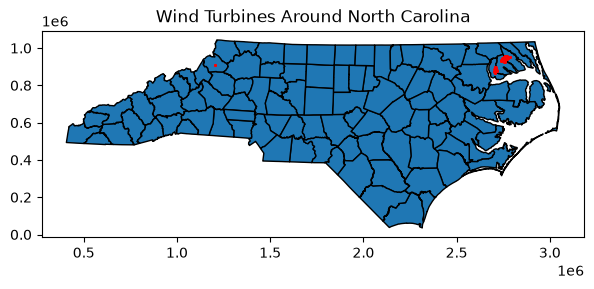

In [8]:
# Plotting wind turbines NC
fig, ax = plt.subplots(figsize=(7,7))
nc_counties.plot(ax=ax, edgecolor="black")
wind_points.plot(ax=ax, markersize=1, c="red")
ax.set_title("Wind Turbines Around North Carolina")
plt.show()

## United States

In [9]:
# US county and state boundaries

us_counties = counties[~counties["STATEFP"].isin(["60", "66", "69", "72", "78"])].to_crs(epsg=2163).copy()
us_states = gpd.read_file(url_0 + url_state)
us_states = us_states[~us_states["STATEFP"].isin(["60", "66", "69", "72", "78"])].to_crs(epsg=2163).copy()


In [10]:
# Spatial join

us_wind = wind.to_crs(epsg=2163).copy()
us_wind_by_county = gpd.sjoin(us_wind, us_counties, predicate="within")
us_wind_by_county


,t_state,p_name,geometry,index_right,STATEFP,COUNTYFP,COUNTYNS,GEOIDFQ,GEOID,NAME,NAMELSAD,STUSPS,STATE_NAME,LSAD,ALAND,AWATER
0,OK,25 Mile Creek,POINT (21786.702 -945228.866),3100,40,045,01101810,0500000US40045,40045,Ellis,Ellis County,OK,Oklahoma,06,3189509979,952235
1,OK,25 Mile Creek,POINT (18777.834 -950763.458),3100,40,045,01101810,0500000US40045,40045,Ellis,Ellis County,OK,Oklahoma,06,3189509979,952235
2,OK,25 Mile Creek,POINT (23934.101 -945419.853),3100,40,045,01101810,0500000US40045,40045,Ellis,Ellis County,OK,Oklahoma,06,3189509979,952235
3,OK,25 Mile Creek,POINT (21455.8 -952058.335),3100,40,045,01101810,0500000US40045,40045,Ellis,Ellis County,OK,Oklahoma,06,3189509979,952235
4,OK,25 Mile Creek,POINT (23939.483 -949619.928),3100,40,045,01101810,0500000US40045,40045,Ellis,Ellis County,OK,Oklahoma,06,3189509979,952235
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
77834,NY,unknown Wyoming County,POINT (1755303.161 -14411.563),3159,36,121,00974158,0500000US36121,36121,Wyoming,Wyoming County,NY,New York,06,1535086366,9085228
77835,NY,unknown Wyoming County,POINT (1746822.912 -41823.138),3159,36,121,00974158,0500000US36121,36121,Wyoming,Wyoming County,NY,New York,06,1535086366,9085228
77836,TX,unknown Young County 1,POINT (135699.883 -1320433.792),1334,48,503,01384037,0500000US48503,48503,Young,Young County,TX,Texas,06,2368539758,42371869
77837,CO,unknown Yuma County,POINT (-231468.577 -547829.483),1374,08,125,00198178,0500000US08125,08125,Yuma,Yuma County,CO,Colorado,06,6123764029,11134195


In [11]:
# Wind turbine count in each US county

us_wind_count = us_wind_by_county["GEOID"].value_counts()


In [12]:
# Creating new table

us_wind_count_table = us_wind_count.reset_index()
us_wind_count_table.columns = ["GEOID", "Wind Turbines"]
us_wind_count_table

,GEOID,Wind Turbines
0,06029,3250
1,48353,1349
2,35057,963
3,08063,753
4,41021,736
...,...,...
707,31157,1
708,38085,1
709,53061,1
710,06107,1


In [13]:
# Add count to all US counties

final_us_wind_count = us_counties.merge(us_wind_count_table, on="GEOID", how="left")
final_us_wind_count["Wind Turbines"] = final_us_wind_count["Wind Turbines"].fillna(0)
final_us_wind_count["Wind Turbines"] = final_us_wind_count["Wind Turbines"].astype(int)

# Filtering for only needed columns
final_us_wind_count = final_us_wind_count[["GEOID", "NAME", "STATEFP", "geometry", "Wind Turbines"]].copy()
final_us_wind_count

,GEOID,NAME,STATEFP,geometry,Wind Turbines
0,01069,Houston,01,"POLYGON ((1361243.071 -1417761.973, 1361482.77...",0
1,01023,Choctaw,01,"POLYGON ((1091349.873 -1380753.078, 1091285.23...",0
2,01113,Russell,01,"POLYGON ((1369020.235 -1290518.673, 1367865.72...",0
3,10005,Sussex,10,"POLYGON ((2068981.843 -379617, 2077670.746 -37...",1
4,01071,Jackson,01,"MULTIPOLYGON (((1266658.34 -1058413.483, 12670...",0
...,...,...,...,...,...
3139,31161,Sheridan,31,"POLYGON ((-227765.059 -238224.635, -227041.887...",0
3140,17119,Madison,17,"POLYGON ((839925.316 -624918.585, 839788.343 -...",0
3141,28155,Webster,28,"POLYGON ((972132.179 -1192052.24, 982580.877 -...",0
3142,29161,Phelps,29,"POLYGON ((701372.858 -776960.721, 701523.172 -...",0


### Plotting US Turbines

In [14]:
# Selecting needed columns
us_wind_points = us_wind_by_county[["p_name", "STATEFP", "geometry"]].copy()

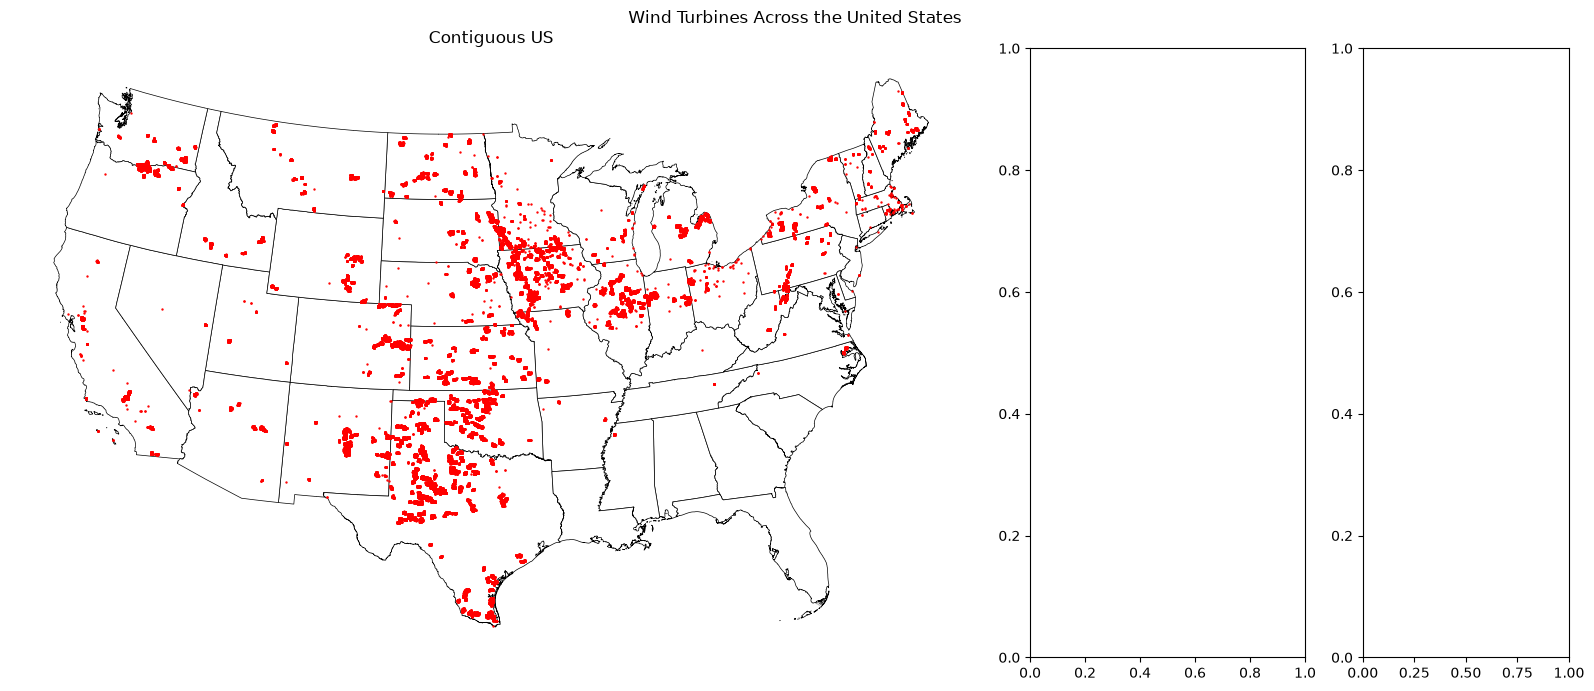

In [15]:
# Plotting wind turbines around the US

fig, axes = plt.subplots(1, 3, figsize=(16, 7), gridspec_kw={"width_ratios": [7, 2, 1.5]})

for ax, state_codes, title in [
    (axes[0], ["02", "15"], "Contiguous US"),
]:
    if title == "Contiguous US":
        area_states = us_states[~us_states["STATEFP"].isin(state_codes)]
        area_wind = us_wind_points[~us_wind_points["STATEFP"].isin(state_codes)]

    area_states.plot(ax=ax, edgecolor="black", facecolor="white", linewidth=0.5)
    if not area_wind.empty:
        area_wind.plot(ax=ax, markersize=0.5 if title == "Contiguous US" else 2, color="red")
    ax.set_title(title)
    ax.set_axis_off()

fig.suptitle("Wind Turbines Across the United States")
plt.tight_layout()
plt.show()
